# 02: RNA-Seq Preprocessing

Full preprocessing pipeline from raw STAR count files to a selected feature matrix for LUAD vs LUSC classification.

**Pipeline**
| Step | Action |
|------|--------|
| 1 | Discover all STAR `.tsv` files (LUAD + LUSC) |
| 2 | Map file UUIDs tp patient barcodes via GDC API |
| 3 | Parse raw counts — extract `unstranded`, keep `protein_coding`, skip STAR summary rows |
| 4 | Build patient × gene count matrix |
| 5 | Load labels and align cohort |
| 6 | Load train/test split |
| 7 | Low-expression filter (train set only) |
| 8 | log2(count + 1) normalization |
| 9 | DEG analysis: Welch t-test, BH correction, |LFC| ≥ 1, padj ≤ 0.05 |
| 10 | Volcano plot and expression heatmap |
| 11 | ExtraTreesClassifier feature selection (train only, 95% cumulative importance) |
| 12 | Save final feature matrix |

> **Output:** `rna_selected_features.csv`, (N_patients × K genes)

## Imports and configurations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import requests
import json
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.ensemble import ExtraTreesClassifier
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Paths
import os

BASE_DIR = Path(
    os.environ.get("FUSION_REPO_DIR", str(Path.cwd()))
).expanduser().resolve()

if BASE_DIR.name in {"Preprocessing", "Training"}:
    BASE_DIR = BASE_DIR.parent

if not (BASE_DIR / "Training" / "07_controlled_early_late_fusion.ipynb").is_file():
    raise RuntimeError(
        "Start Jupyter from the repository directory or set FUSION_REPO_DIR."
    )
DATA_DIR = Path(
    os.environ.get("FUSION_DATA_DIR", str(BASE_DIR / "Data"))
).expanduser().resolve()
RNA_DIR  = DATA_DIR / 'rna'

OUT_DIR = BASE_DIR / "Preprocessing"
FIG_DIR  = OUT_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

LABELS_PATH = DATA_DIR / "multiomics_labels.tsv"
SPLIT_PATH    = DATA_DIR / 'train_test_split.csv'
OUT_PATH      = OUT_DIR  / 'rna_selected_features.csv'
SELECTOR_PATH = OUT_DIR  / 'rna_selected_genes.txt'
CACHE_PATH    = OUT_DIR  / 'rna_uuid_barcode_map.json'

In [3]:
# Configurations
RANDOM_STATE      = 42
MIN_NONZERO_FRAC  = 0.20   # gene must be non-zero in >=20% of training samples
MIN_MEAN_COUNT    = 10     # gene must have mean raw count >=10 in training samples
LFC_THRESHOLD     = 1.0    # |log2 fold change| threshold
PVAL_THRESHOLD    = 0.05   # BH-adjusted p-value threshold
IMPORTANCE_THRESH = 0.95   # cumulative importance threshold for feature selection
GDC_API           = 'https://api.gdc.cancer.gov'

In [4]:
print('Imports OK')
print(f'RNA dir  : {RNA_DIR}')
print(f'Output   : {OUT_PATH}')

Imports OK
RNA dir  : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Data/rna
Output   : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/rna_selected_features.csv


## 1. Discover all STAR `.tsv` files

In [5]:
luad_files = list((RNA_DIR / 'TCGA-LUAD').rglob('*.rna_seq.augmented_star_gene_counts.tsv'))
lusc_files = list((RNA_DIR / 'TCGA-LUSC').rglob('*.rna_seq.augmented_star_gene_counts.tsv'))
all_files  = luad_files + lusc_files

# UUID is the parent folder name
file_uuid_map = {f.parent.name: f for f in all_files}

print(f'LUAD files : {len(luad_files)}')
print(f'LUSC files : {len(lusc_files)}')
print(f'Total      : {len(all_files)}')
print(f'\nExample UUID : {all_files[0].parent.name}')
print(f'Example path : {all_files[0]}')

LUAD files : 455
LUSC files : 370
Total      : 825

Example UUID : 0052ae83-7ae5-470a-a125-5cd94a9fa9e9
Example path : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Data/rna/TCGA-LUAD/Transcriptome_Profiling/Gene_Expression_Quantification/0052ae83-7ae5-470a-a125-5cd94a9fa9e9/a6a6b9c6-9db7-42b3-a09f-770b7e126fbb.rna_seq.augmented_star_gene_counts.tsv


## 2. Map file UUIDs to patient barcodes via GDC API

Queried in batches of 1000. Results are cached to `rna_uuid_barcode_map.json` so subsequent runs skip the API calls.

In [6]:
def query_gdc_batch(uuids):
    payload = {
        'filters': json.dumps({
            'op': 'in',
            'content': {'field': 'file_id', 'value': uuids}
        }),
        'fields': 'file_id,cases.submitter_id',
        'format': 'json',
        'size'   : str(len(uuids))
    }
    r = requests.post(f'{GDC_API}/files', data=payload, timeout=60)
    r.raise_for_status()
    result = {}
    for hit in r.json()['data']['hits']:
        fid   = hit['file_id']
        cases = hit.get('cases', [])
        if cases:
            result[fid] = cases[0]['submitter_id'][:12].upper()
    return result

if CACHE_PATH.exists():
    with open(CACHE_PATH) as f:
        uuid_to_patient = json.load(f)
    print(f'Loaded cached UUID map : {len(uuid_to_patient)} entries')
else:
    uuid_to_patient = {}
    uuids = list(file_uuid_map.keys())
    for i in tqdm(range(0, len(uuids), 1000), desc='GDC API'):
        uuid_to_patient.update(query_gdc_batch(uuids[i:i+1000]))
    with open(CACHE_PATH, 'w') as f:
        json.dump(uuid_to_patient, f)
    print(f'Mapped {len(uuid_to_patient)} / {len(uuids)} files to patient barcodes')

Loaded cached UUID map : 825 entries


## 3. Parse raw counts from all files

For each file:
- Skip STAR summary rows (`N_unmapped`, `N_multimapping`, `N_noFeature`, `N_ambiguous`)
- Keep `protein_coding` genes only
- Extract `unstranded` raw count column
- Strip Ensembl version numbers from gene IDs

In [7]:
STAR_SKIP = {'N_unmapped', 'N_multimapping', 'N_noFeature', 'N_ambiguous'}

def parse_star_file(filepath):
    df = pd.read_csv(filepath, sep='\t', comment='#',
                     usecols=['gene_id', 'gene_type', 'unstranded'])
    df = df[~df['gene_id'].isin(STAR_SKIP)]
    df = df[df['gene_type'] == 'protein_coding']
    df['gene_id'] = df['gene_id'].str.split('.').str[0]
    df = df.drop_duplicates(subset='gene_id').set_index('gene_id')
    return df['unstranded'].astype(float)

counts_dict = {}
skipped     = []

for uuid, filepath in tqdm(file_uuid_map.items(), desc='Parsing files'):
    patient_id = uuid_to_patient.get(uuid)
    if patient_id is None:
        skipped.append(uuid); continue
    if patient_id in counts_dict:
        continue  # one sample per patient
    try:
        counts_dict[patient_id] = parse_star_file(filepath)
    except Exception as e:
        skipped.append(uuid)

print(f'Patients parsed : {len(counts_dict)}')
print(f'Skipped         : {len(skipped)}')

Parsing files: 100%|██████████| 825/825 [00:57<00:00, 14.27it/s]

Patients parsed : 825
Skipped         : 0


## 4. Build patient × gene count matrix

In [8]:
df_counts = pd.DataFrame(counts_dict).T
df_counts.index.name = 'patient_id'
df_counts = df_counts.fillna(0)

print(f'Count matrix shape : {df_counts.shape}  (patients × genes)')
print(f'NaNs               : {df_counts.isnull().sum().sum()}')

Count matrix shape : (825, 19944)  (patients × genes)
NaNs               : 0


## 5. Load labels and align cohort

In [9]:
df_labels = pd.read_csv(LABELS_PATH, sep='\t', index_col='patient_id')
df_labels.index = df_labels.index.str.strip().str.upper().str[:12]
labels = df_labels['subtype_simple'].map({'LUAD': 0, 'LUSC': 1})

common_ids = df_counts.index.intersection(labels.index)
df_counts  = df_counts.loc[common_ids]
y          = labels.loc[common_ids]

print(f'Patients after intersection : {len(common_ids)}')
print(f'LUAD: {(y==0).sum()}, LUSC: {(y==1).sum()}')

Patients after intersection : 825
LUAD: 455, LUSC: 370


## 6. Load train/test split

In [10]:
assert SPLIT_PATH.exists(), f'Split file not found: {SPLIT_PATH}. Run notebook 01 first.'
split_df  = pd.read_csv(SPLIT_PATH, index_col='patient_id')
split_df.index = split_df.index.str.strip().str.upper().str[:12]
split_df  = split_df.loc[split_df.index.intersection(common_ids)]

train_ids = split_df[split_df['split'] == 'train'].index
test_ids  = split_df[split_df['split'] == 'test'].index

print(f'Train : {len(train_ids)}')
print(f'Test  : {len(test_ids)}')

Train : 578
Test  : 247


## 7. Low-expression filter (train set only)

Both criteria computed on training patients only, then applied to the full cohort.

In [11]:
train_counts = df_counts.loc[train_ids]
nonzero_frac = (train_counts > 0).mean(axis=0)
mean_count   = train_counts.mean(axis=0)

keep_genes = nonzero_frac[
    (nonzero_frac >= MIN_NONZERO_FRAC) & (mean_count >= MIN_MEAN_COUNT)
].index

df_counts = df_counts[keep_genes]

print(f'Genes before filter : {len(nonzero_frac)}')
print(f'Genes after filter  : {len(keep_genes)}')

Genes before filter : 19944
Genes after filter  : 16684


## 8. log2(count + 1) normalization

Normalized shape : (825, 16684)


Value range      : [0.000, 22.391]


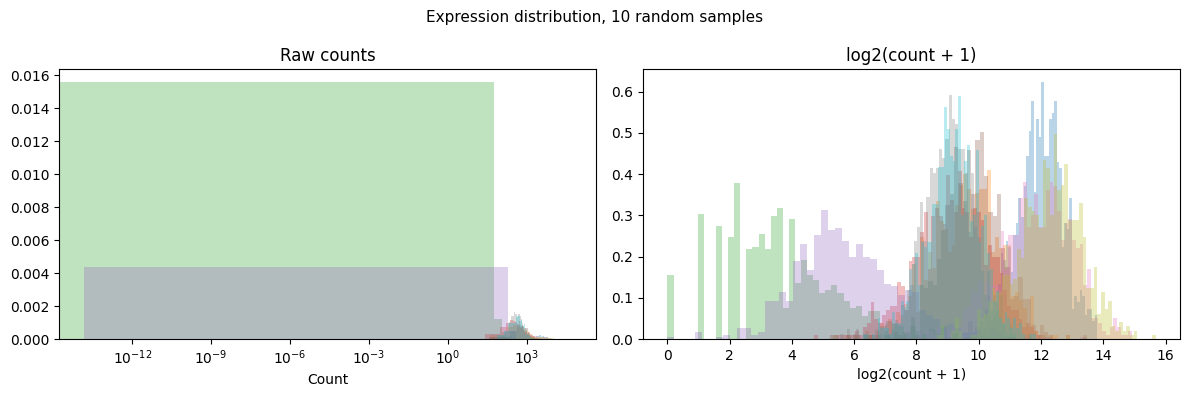

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/rna_normalization.png


In [12]:
df_log = np.log2(df_counts + 1)

print(f'Normalized shape : {df_log.shape}')
print(f'Value range      : [{df_log.values.min():.3f}, {df_log.values.max():.3f}]')

# Distribution before and after
np.random.seed(RANDOM_STATE)
sample_cols = np.random.choice(df_counts.columns, size=10, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col in sample_cols:
    axes[0].hist(df_counts[col], bins=60, alpha=0.3, density=True)
axes[0].set_xscale('log'); axes[0].set_title('Raw counts'); axes[0].set_xlabel('Count')
for col in sample_cols:
    axes[1].hist(df_log[col], bins=60, alpha=0.3, density=True)
axes[1].set_title('log2(count + 1)'); axes[1].set_xlabel('log2(count + 1)')
plt.suptitle('Expression distribution, 10 random samples', fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / 'rna_normalization.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/rna_normalization.png')

## 9. Differential expression analysis, Welch t-test (train set only)

DEG analysis computed on training patients only to prevent leakage.
Significant DEGs: |LFC| ≥ 1.0 AND padj ≤ 0.05 (Benjamini-Hochberg correction).

In [13]:
train_log = df_log.loc[train_ids]
X_luad    = train_log.loc[y.loc[train_ids] == 0]
X_lusc    = train_log.loc[y.loc[train_ids] == 1]

print('Running Welch t-test...')
t_stats, p_vals = stats.ttest_ind(X_lusc.values, X_luad.values, axis=0, equal_var=False)
_, padj, _, _   = multipletests(p_vals, method='fdr_bh')
lfc             = X_lusc.mean(axis=0).values - X_luad.mean(axis=0).values

deg_df   = pd.DataFrame({'lfc': lfc, 'pval': p_vals, 'padj': padj},
                         index=df_log.columns)
sig_mask = (deg_df['padj'] <= PVAL_THRESHOLD) & (deg_df['lfc'].abs() >= LFC_THRESHOLD)
deg_sig  = deg_df[sig_mask].sort_values('lfc', ascending=False)

print(f'Total genes tested     : {len(deg_df)}')
print(f'Upregulated in LUSC    : {(deg_sig["lfc"] > 0).sum()}')
print(f'Upregulated in LUAD    : {(deg_sig["lfc"] < 0).sum()}')
print(f'Total DEGs             : {len(deg_sig)}')

Running Welch t-test...
Total genes tested     : 16684
Upregulated in LUSC    : 1737
Upregulated in LUAD    : 1080
Total DEGs             : 2817


### 9a. Volcano plot

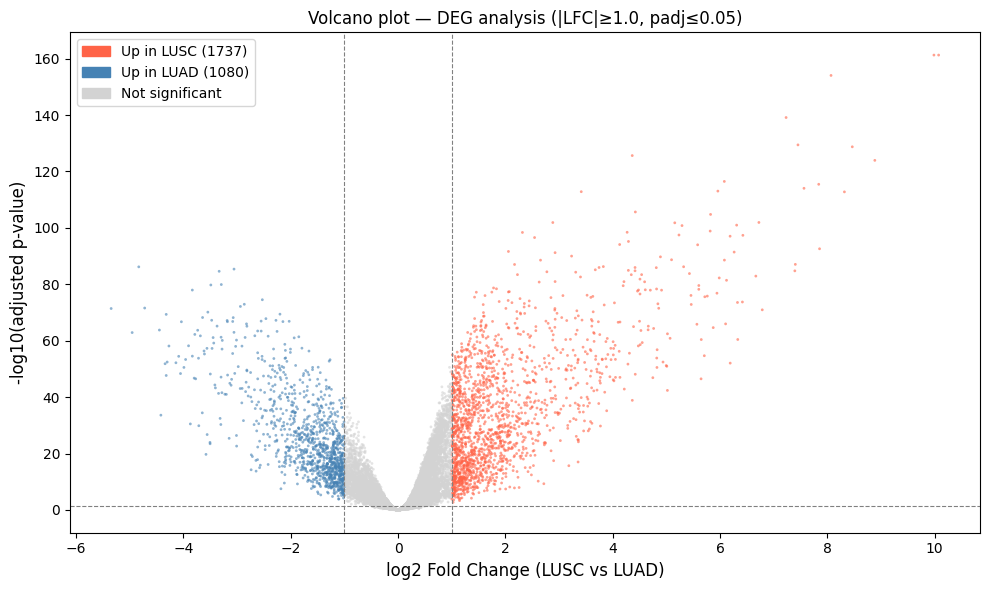

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/rna_volcano_plot.png


In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
neg_log_p = -np.log10(deg_df['padj'].clip(lower=1e-300))
colors    = np.where(sig_mask & (deg_df['lfc'] > 0), 'tomato',
            np.where(sig_mask & (deg_df['lfc'] < 0), 'steelblue', 'lightgrey'))
ax.scatter(deg_df['lfc'], neg_log_p, c=colors, s=4, alpha=0.6, linewidths=0)
ax.axvline( LFC_THRESHOLD, color='grey', linestyle='--', linewidth=0.8)
ax.axvline(-LFC_THRESHOLD, color='grey', linestyle='--', linewidth=0.8)
ax.axhline(-np.log10(PVAL_THRESHOLD), color='grey', linestyle='--', linewidth=0.8)
lusc_p = mpatches.Patch(color='tomato',    label=f'Up in LUSC ({(sig_mask & (deg_df["lfc"]>0)).sum()})')
luad_p = mpatches.Patch(color='steelblue', label=f'Up in LUAD ({(sig_mask & (deg_df["lfc"]<0)).sum()})')
ns_p   = mpatches.Patch(color='lightgrey', label='Not significant')
ax.legend(handles=[lusc_p, luad_p, ns_p], fontsize=10)
ax.set_xlabel('log2 Fold Change (LUSC vs LUAD)', fontsize=12)
ax.set_ylabel('-log10(adjusted p-value)', fontsize=12)
ax.set_title(f'Volcano plot — DEG analysis (|LFC|≥{LFC_THRESHOLD}, padj≤{PVAL_THRESHOLD})', fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / 'rna_volcano_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/rna_volcano_plot.png')

### 9b. Filter full matrix to DEGs only

In [15]:
deg_genes = deg_sig.index.tolist()
df_deg    = df_log[deg_genes].copy()
print(f'DEG matrix shape : {df_deg.shape}  (patients × DEGs)')

DEG matrix shape : (825, 2817)  (patients × DEGs)


## 10. ExtraTreesClassifier feature selection (train set only)

Fitted on training patients only to rank DEGs by importance.
Features retained until 95% cumulative importance is covered.

In [20]:
X_train = df_deg.loc[train_ids]
y_train = y.loc[train_ids]

print(f'X_train : {X_train.shape}')
print('Fitting ExtraTreesClassifier...')

etc = ExtraTreesClassifier(
    n_estimators=500,
    max_features='sqrt',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
etc.fit(X_train, y_train)

# Map Ensembl IDs to gene names using the first parsed file
sample_file   = next(iter(file_uuid_map.values()))
gene_name_map = (
    pd.read_csv(sample_file, sep='\t', comment='#',
                usecols=['gene_id', 'gene_name', 'gene_type'])
    .query("gene_type == 'protein_coding'")
    .assign(gene_id=lambda x: x['gene_id'].str.split('.').str[0])
    .drop_duplicates('gene_id')
    .set_index('gene_id')['gene_name']
)

# Rename df_deg columns to gene names before computing importances
df_deg.columns = [gene_name_map.get(g, g) for g in df_deg.columns]

importances = pd.Series(etc.feature_importances_, index=df_deg.columns)
importances = importances.sort_values(ascending=False)
cumulative  = importances.cumsum() / importances.sum()

N_TOP_GENES = 100
n_selected  = N_TOP_GENES
top_genes   = importances.iloc[:n_selected].index.tolist()
coverage    = cumulative.iloc[n_selected - 1]

print(f'\nDEGs input       : {len(importances)}')
print(f'Genes selected   : {n_selected}')
print(f'Importance cover : {coverage:.2%}')
print(f'\nTop 20 selected genes:')
for i, (gene, imp) in enumerate(importances.iloc[:20].items(), 1):
    print(f'  {i:>2}. {gene:<25} importance={imp:.5f}')

X_train : (578, 2817)
Fitting ExtraTreesClassifier...

DEGs input       : 2817
Genes selected   : 100
Importance cover : 46.11%

Top 20 selected genes:
   1. DSC3                      importance=0.01586
   2. DSG3                      importance=0.01582
   3. KRT74                     importance=0.01462
   4. KRT5                      importance=0.01356
   5. CERS3                     importance=0.01216
   6. KRT6C                     importance=0.01101
   7. CLCA2                     importance=0.01063
   8. SERPINB13                 importance=0.00977
   9. CALML3                    importance=0.00921
  10. KRT31                     importance=0.00840
  11. KRT6A                     importance=0.00805
  12. NECTIN1                   importance=0.00761
  13. DAPL1                     importance=0.00735
  14. TP63                      importance=0.00730
  15. KRT13                     importance=0.00685
  16. SERPINB2                  importance=0.00670
  17. KRT6B                     

### 10a. Feature importance visualization

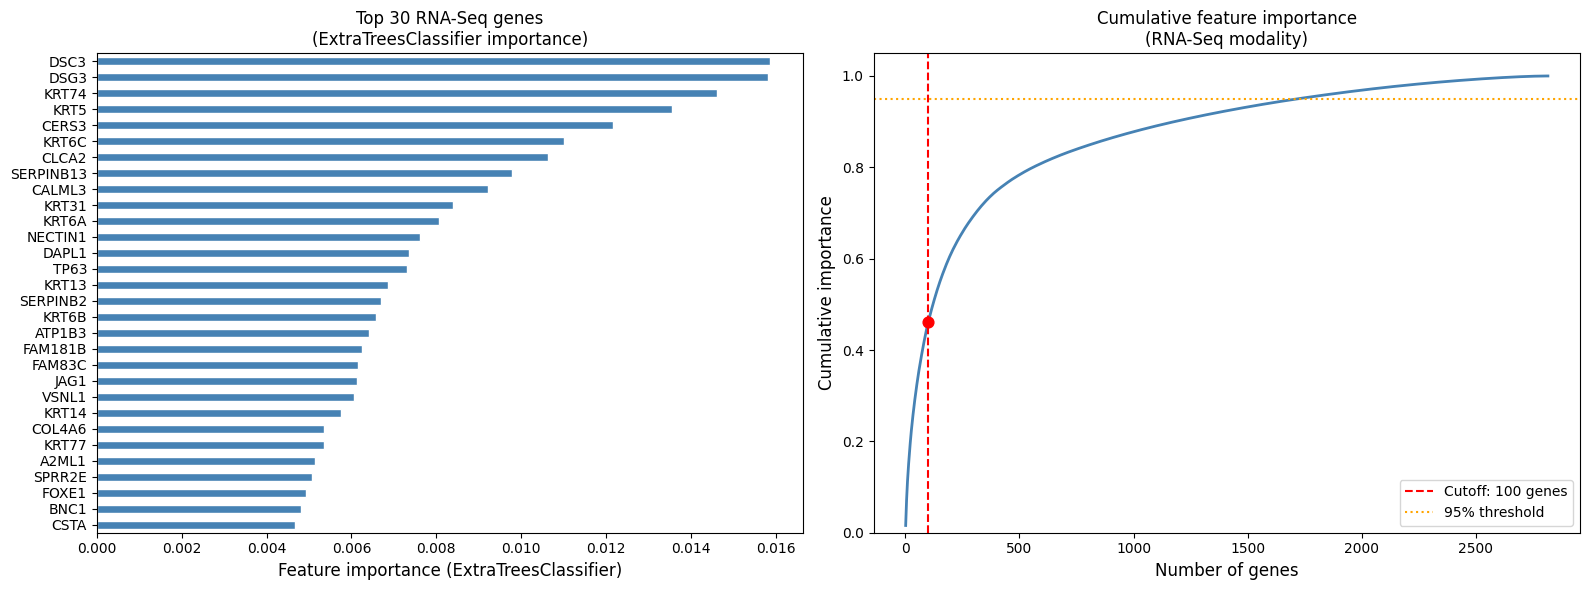

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/rna_feature_importance.png


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
importances.iloc[:30].sort_values().plot(
    kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Feature importance (ExtraTreesClassifier)', fontsize=12)
ax.set_title('Top 30 RNA-Seq genes\n(ExtraTreesClassifier importance)', fontsize=12)

ax2 = axes[1]
ax2.plot(range(1, len(cumulative) + 1), cumulative.values, color='steelblue', linewidth=2)
ax2.axvline(n_selected, color='red', linestyle='--', linewidth=1.5,
            label=f'Cutoff: {n_selected} genes')
ax2.axhline(IMPORTANCE_THRESH, color='orange', linestyle=':', linewidth=1.5,
            label=f'{IMPORTANCE_THRESH:.0%} threshold')
ax2.scatter([n_selected], [coverage], color='red', zorder=5, s=60)
ax2.set_xlabel('Number of genes', fontsize=12)
ax2.set_ylabel('Cumulative importance', fontsize=12)
ax2.set_title('Cumulative feature importance\n(RNA-Seq modality)', fontsize=12)
ax2.legend(fontsize=10)
ax2.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(FIG_DIR / 'rna_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/rna_feature_importance.png')

### 10b. Expression heatmap of top selected genes

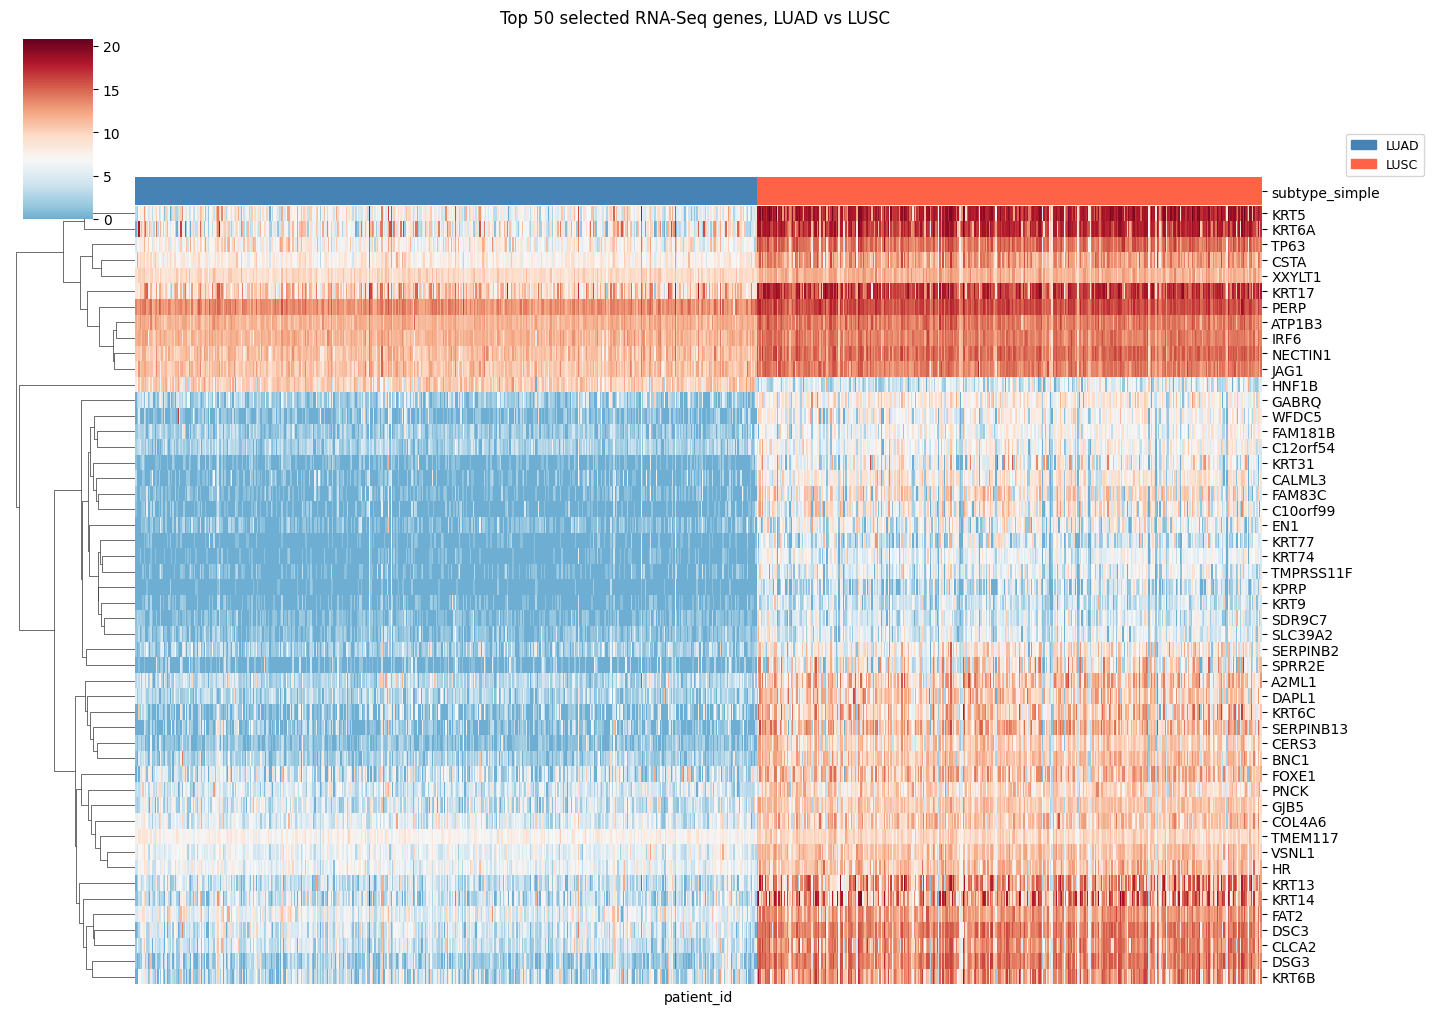

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/rna_expression_heatmap.png


In [22]:
top_plot      = top_genes[:min(50, n_selected)]
patient_order = y.sort_values().index
df_heat       = df_deg[top_plot].loc[patient_order].T
subtype_colors = y.loc[patient_order].map({0: 'steelblue', 1: 'tomato'})

g = sns.clustermap(
    df_heat,
    col_colors       = subtype_colors,
    cmap             = 'RdBu_r',
    center           = df_heat.values.mean(),
    yticklabels      = True,
    xticklabels      = False,
    figsize          = (14, 10),
    dendrogram_ratio = (0.1, 0.15),
    col_cluster      = False,
)
g.fig.suptitle(f'Top {len(top_plot)} selected RNA-Seq genes, LUAD vs LUSC', y=1.01, fontsize=12)
luad_patch = mpatches.Patch(color='steelblue', label='LUAD')
lusc_patch = mpatches.Patch(color='tomato',    label='LUSC')
g.ax_heatmap.legend(handles=[luad_patch, lusc_patch],
                    loc='upper right', bbox_to_anchor=(1.15, 1.1), fontsize=9)
plt.savefig(FIG_DIR / 'rna_expression_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/rna_expression_heatmap.png')

In [23]:
df_final = df_deg[top_genes].copy()

df_final.to_csv(OUT_PATH)
print(f'Saved feature matrix to {OUT_PATH}')
print(f'Shape                : {df_final.shape}  (patients × genes)')

with open(SELECTOR_PATH, 'w') as f:
    f.write('\n'.join(top_genes))
print(f'Gene names saved     to {SELECTOR_PATH}')

print(f'\nSelected : {n_selected} genes  to  {coverage:.2%} of total importance')
print(f'Dropped  : {len(importances) - n_selected} DEGs  to  {1-coverage:.2%} (noise tail)')

Saved feature matrix to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/rna_selected_features.csv
Shape                : (825, 100)  (patients × genes)
Gene names saved     to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/rna_selected_genes.txt

Selected : 100 genes  to  46.11% of total importance
Dropped  : 2717 DEGs  to  53.89% (noise tail)


## Summary

| Step | Result |
|------|--------|
| Raw files (LUAD + LUSC) | 455 + 370 = 825 |
| Protein-coding genes | 19,944 |
| After low-expression filter | 16,684 |
| After DEG filter (\|LFC\|≥1, padj≤0.05) | 2,817 |
| **Final selected genes** | **200 (top-N by ExtraTreesClassifier importance, 61% coverage)** |
| Output file | `rna_selected_features.csv` |
| Feature selection | ExtraTreesClassifier, 500 trees, top 200 genes, train set only |
| Leakage prevention | Low-expression filter, DEG analysis, and feature selector all computed on train patients only |